# Sensores IoT: Ocupação das Salas

Em um complexo tecnológico e industrial, que está equipado com sensores ambientais IoT, se faz necessário prever em tempo real se salas técnicas e escritórios estão ocupados ou não, a fim de automatizar sistemas inteligentes de iluminação e ar-condicionado (HVAC), visando redução de custos com energia.

A variável alvo do projeto é binária: `Occupancy` = 1 (ambiente ocupado / ativo) e `Occupancy` = 0 (ambiente desocupado / inativo).

**Base de Dados**: Occupancy Detection Dataset (UCI Machine Learning Repository / Kaggle), composta pelas seguintes variáveis ambientais:
- `Temperature`: Temperatura do ambiente em graus Celsius (°C).
- `Humidity`: Umidade relativa do ar (%).
- `Light`: Nível de luminosidade medido pelo sensor (Lux).
- `CO2`: Concentração de dióxido de carbono no ar (ppm).
- `HumidityRatio`: Taxa derivada de umidade específica e temperatura.
- `Occupancy` (Variável Alvo): Indicador binário de presença (0 = Desocupado, 1 = Ocupado).


**Objetivo do Projeto:**

Comparar KNN e Árvore de Decisão e escolher o modelo para a automação predial.


**Fases do Projeto:**
- Fase 1: Análise Exploratória (EDA)
- Fase 2: Limpeza e Tratamento de Dados (Data Prep)
- Fase 3: Feature Engineering
- Fase 4: Divisão e Balanceamento dos Dados
- Fase 5: Escalonamento de Variáveis (StandardScaler)
- Fase 6: Ajuste de Parâmetros e Combate ao Overfitting
- Fase 7: Avaliação da Acurácia e Veredito Final



### Importação das bibliotecas

Importar as bibliotecas utilizadas em todo o projeto:

- **pandas** e **numpy**: leitura e manipulação dos dados.
- **matplotlib** e **seaborn**: criação dos gráficos da análise exploratória.
- **scikit-learn** (Machine Learning):
  - `train_test_split`: divisão da base em treino e teste;
  - `StandardScaler`: padronização da escala das variáveis para o KNN;
  - `KNeighborsClassifier` e `DecisionTreeClassifier`: os dois modelos comparados;
  - `accuracy_score`, `classification_report` e `confusion_matrix`: avaliação dos modelos.
- **os**, **zipfile** e **urllib.request**: download e extração da base de dados.

Também são definidas as configurações visuais padrão dos gráficos (fundo sem grade e tamanho da figura).

In [1]:
# Bibliotecas
import os
import zipfile
import urllib.request
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler

# Configurações visuais para os gráficos
sns.set_theme(style="white")
plt.rcParams["figure.figsize"] = (10, 5)

## Fase 1: Análise Exploratória (EDA)

Antes de treinar qualquer modelo, é preciso conhecer a base: quantas linhas e colunas existem, quais são os tipos de dados, como os valores se distribuem e como as variáveis se relacionam com a ocupação da sala. Essa etapa orienta todas as decisões das fases seguintes.

### Carregamento da base de dados

**Fonte:** Occupancy Detection Dataset, disponível no UCI Machine Learning Repository.

A base é baixada diretamente do repositório da UCI, em vez da versão disponibilizada em planilha online. A versão em planilha apresentou problemas de formatação: ao ser importada com configuração regional em português, o ponto decimal foi interpretado como separador de milhar, e valores como `0.0047` em `HumidityRatio` passaram a aparecer como números inteiros muito grandes. O arquivo original da UCI não passa por nenhuma planilha e preserva os valores corretos.

O arquivo baixado contém três partes da mesma coleta (`datatraining.txt`, `datatest.txt` e `datatest2.txt`). As três são lidas e unidas em um único DataFrame, formando a base completa, que é salva em `data/occupancy_completo.csv`.

O download acontece apenas na primeira execução: se o arquivo já existir na pasta `data/`, o código pula direto para a leitura. Todos os caminhos são relativos à pasta do notebook, para que o projeto rode em qualquer computador.

In [2]:
caminho_csv = "../data/occupancy_completo.csv"

# Baixar e extrair a base da UCI apenas se o arquivo final ainda não existir
if not os.path.exists(caminho_csv):
    url_uci = "https://archive.ics.uci.edu/ml/machine-learning-databases/00357/occupancy_data.zip"
    zip_path = "../data/occupancy_data.zip"
    urllib.request.urlretrieve(url_uci, zip_path)

    with zipfile.ZipFile(zip_path, "r") as zip_ref:
        zip_ref.extractall("../data/raw")

    # Ler as três partes da base
    df_treino = pd.read_csv("../data/raw/datatraining.txt")
    df_teste1 = pd.read_csv("../data/raw/datatest.txt")
    df_teste2 = pd.read_csv("../data/raw/datatest2.txt")

    # Unir as três partes em um único DataFrame
    df_completo = pd.concat([df_treino, df_teste1, df_teste2], ignore_index=True)

    # Salvar a base completa
    df_completo.to_csv(caminho_csv, index=False)

# Carregar a base completa
df = pd.read_csv(caminho_csv)
print("Base de dados carregada com sucesso!")

Base de dados carregada com sucesso!


In [3]:
df.head(10)

,date,Temperature,Humidity,Light,CO2,HumidityRatio,Occupancy
0,2015-02-04 17:51:00,23.180,27.2720,426.0,721.250000,0.004793,1
1,2015-02-04 17:51:59,23.150,27.2675,429.5,714.000000,0.004783,1
2,2015-02-04 17:53:00,23.150,27.2450,426.0,713.500000,0.004779,1
3,2015-02-04 17:54:00,23.150,27.2000,426.0,708.250000,0.004772,1
4,2015-02-04 17:55:00,23.100,27.2000,426.0,704.500000,0.004757,1
5,2015-02-04 17:55:59,23.100,27.2000,419.0,701.000000,0.004757,1
6,2015-02-04 17:57:00,23.100,27.2000,419.0,701.666667,0.004757,1
7,2015-02-04 17:57:59,23.100,27.2000,419.0,699.000000,0.004757,1
8,2015-02-04 17:58:59,23.100,27.2000,419.0,689.333333,0.004757,1
9,2015-02-04 18:00:00,23.075,27.1750,419.0,688.000000,0.004745,1


As primeiras linhas confirmam que a base foi carregada corretamente, com sete colunas: a data e hora da medição (`date`), as cinco variáveis dos sensores (`Temperature`, `Humidity`, `Light`, `CO2` e `HumidityRatio`) e a variável alvo `Occupancy`.

Os valores numéricos aparecem com ponto decimal e na escala esperada (por exemplo, `HumidityRatio` com valores próximos de 0,005), sem a distorção observada na versão em planilha.

Os arquivos `.txt` da UCI trazem, no início de cada linha, um número de registro sem nome no cabeçalho. Ao ler os arquivos, o pandas interpretou essa coluna como índice, e não como dado. Na união das três partes, o parâmetro `ignore_index=True` renumerou as linhas em uma sequência única, e o `index=False` impediu que esse índice fosse gravado no arquivo final. Por isso, a base final contém apenas as colunas de interesse.

### Dimensões da base

Verificar quantas linhas (medições) e quantas colunas (variáveis) a base possui. O tamanho da base ajuda a avaliar se há dados suficientes para treinar e testar os modelos.

In [4]:
df.shape

(20560, 7)

A base possui **20.560 linhas** (medições dos sensores) e **7 colunas**. É um volume adequado para treinar e testar modelos de classificação, mesmo após reservar 20% dos dados para o teste.

### Tipos de dados e valores não nulos

Verificar o tipo de cada coluna e a quantidade de valores preenchidos. Os modelos de Machine Learning trabalham apenas com números, então é preciso confirmar que as variáveis dos sensores foram lidas como numéricas e identificar colunas que exigem algum tratamento antes da modelagem. A contagem de valores não nulos também dá uma primeira indicação sobre a existência de dados ausentes, que serão tratados na Fase 2.

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20560 entries, 0 to 20559
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   date           20560 non-null  str    
 1   Temperature    20560 non-null  float64
 2   Humidity       20560 non-null  float64
 3   Light          20560 non-null  float64
 4   CO2            20560 non-null  float64
 5   HumidityRatio  20560 non-null  float64
 6   Occupancy      20560 non-null  int64  
dtypes: float64(5), int64(1), str(1)
memory usage: 1.1 MB


Todas as colunas possuem 20.560 valores preenchidos, ou seja, **não há dados ausentes** na base original. Essa verificação será repetida na Fase 2, com o tratamento adequado.

As cinco variáveis dos sensores (`Temperature`, `Humidity`, `Light`, `CO2` e `HumidityRatio`) foram lidas como números decimais (`float64`), e a variável alvo `Occupancy` como número inteiro (`int64`), o que confirma a leitura correta dos dados.

A única coluna que não é numérica é `date`, lida como texto (`str`). Ela será tratada a seguir.

### Resumo estatístico

Calcular as principais medidas estatísticas das colunas numéricas: contagem, média, desvio padrão, valores mínimo e máximo e quartis (25%, 50% e 75%). Esse resumo mostra a escala de cada sensor, ajuda a identificar possíveis valores extremos e permite comparar média e mediana (50%) para avaliar a simetria das distribuições.

In [6]:
df.describe()

,Temperature,Humidity,Light,CO2,HumidityRatio,Occupancy
count,20560.000000,20560.000000,20560.000000,20560.000000,20560.000000,20560.000000
mean,20.906212,27.655925,130.756622,690.553276,0.004228,0.231031
std,1.055315,4.982154,210.430875,311.201281,0.000768,0.421503
min,19.000000,16.745000,0.000000,412.750000,0.002674,0.000000
25%,20.200000,24.500000,0.000000,460.000000,0.003719,0.000000
50%,20.700000,27.290000,0.000000,565.416667,0.004292,0.000000
75%,21.525000,31.290000,301.000000,804.666667,0.004832,0.000000
max,24.408333,39.500000,1697.250000,2076.500000,0.006476,1.000000


Principais observações do resumo estatístico:

- **`Temperature`** varia pouco: de 19,0 °C a 24,4 °C, com desvio padrão de cerca de 1 °C. Média (20,91) e mediana (20,70) são próximas, indicando uma distribuição quase simétrica.
- **`Humidity`** varia de 16,7% a 39,5%, também com média (27,66) e mediana (27,29) próximas.
- **`Light`** apresenta o comportamento mais marcante: a **mediana é 0**, o que significa que em pelo menos metade das medições a luz estava apagada. Já a média (130,76) e o máximo (1.697,25 Lux) são muito maiores, indicando uma distribuição fortemente assimétrica, com valores altos concentrados em parte dos registros.
- **`CO2`** varia de 412,75 a 2.076,5 ppm, com média (690,55) bem acima da mediana (565,42), o que também indica assimetria à direita: a maior parte das medições tem CO2 mais baixo, e alguns momentos registram valores altos.
- **`HumidityRatio`** tem valores muito pequenos (em torno de 0,004), em uma escala completamente diferente das demais variáveis.
- **`Occupancy`** tem média de 0,231. Como a variável só assume 0 ou 1, isso indica que **cerca de 23% das medições correspondem a salas ocupadas** e 77% a salas vazias. As classes são **desbalanceadas**, o que exige atenção: um modelo que sempre previsse "vazio" já acertaria cerca de 77% dos casos (o Paradoxo da Acurácia). Por isso, a divisão entre treino e teste será feita com estratificação (Fase 4).

A grande diferença de escala entre os sensores (`Light` chega a quase 1.700, enquanto `HumidityRatio` não passa de 0,007) reforça a necessidade de padronizar as variáveis para o KNN, que se baseia em distâncias (Fase 5).

### Tratamento da coluna `date`

A coluna `date` registra a data e a hora de cada medição. Ela será **descartada antes da modelagem** pelos seguintes motivos:

- É uma coluna de texto, e os modelos KNN e Árvore de Decisão trabalham apenas com números.
- Cada valor é praticamente único (um registro por minuto), então o modelo não conseguiria aprender um padrão a partir dela.
- O objetivo do sistema é prever a ocupação **a partir das condições do ambiente medidas pelos sensores**, e não a partir do momento da medição.

Uma melhoria possível seria extrair informações da data, como a hora do dia ou o dia da semana, que podem ter relação com a ocupação. Essa possibilidade fica registrada como melhoria futura.

In [ ]:
df = df.drop(columns="date")
df.shape

Após o descarte de `date`, a base passa a ter 6 colunas: as cinco variáveis dos sensores e a variável alvo `Occupancy`, todas numéricas.

### Distribuição das variáveis preditoras

Plotar o histograma de cada variável dos sensores para observar como os valores se distribuem: se são simétricos, assimétricos, concentrados em uma faixa ou com valores extremos. Essa leitura ajuda a escolher entre média e mediana no tratamento de dados ausentes (Fase 2).

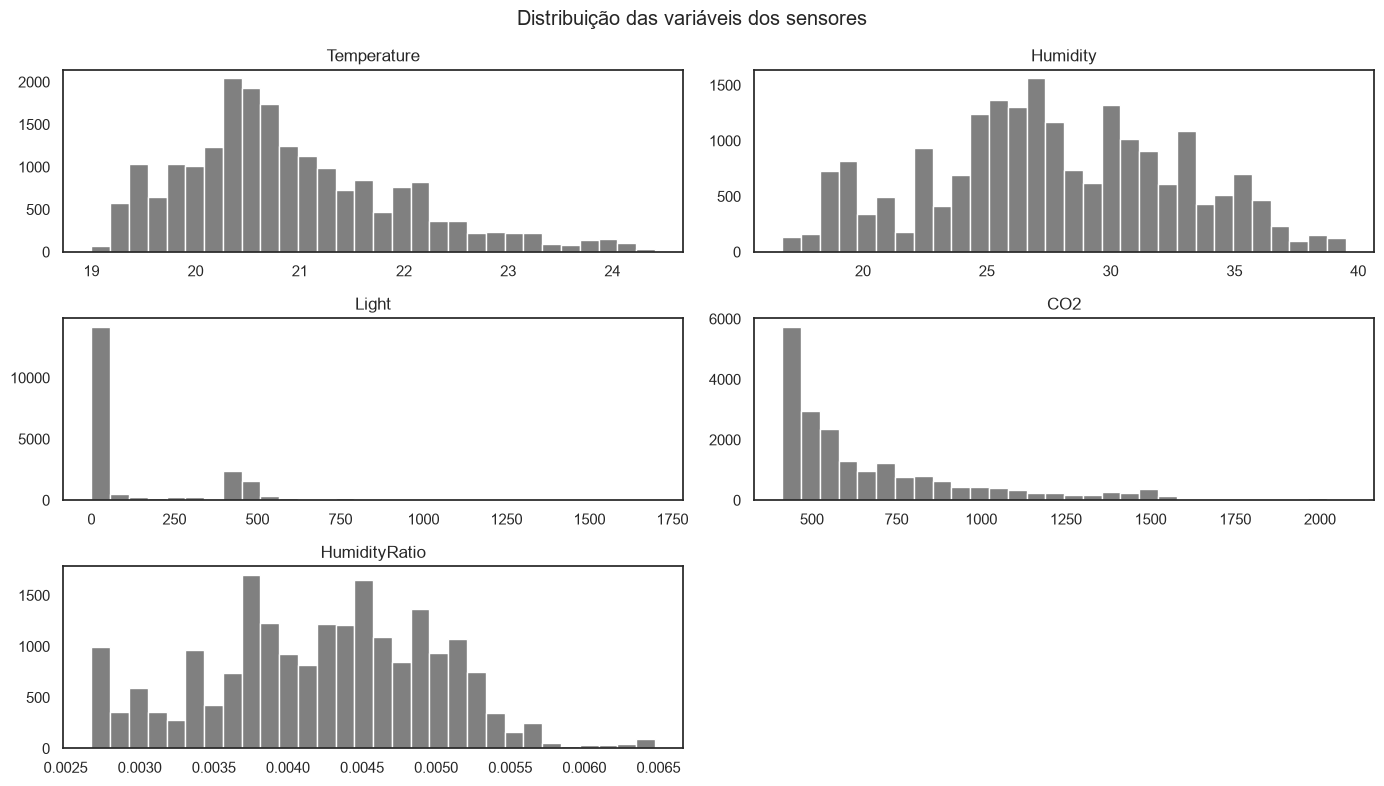

In [9]:
colunas_sensores = ["Temperature", "Humidity", "Light", "CO2", "HumidityRatio"]

df[colunas_sensores].hist(bins=30, figsize=(14, 8), color="gray", edgecolor="white", grid=False)
plt.suptitle("Distribuição das variáveis dos sensores")
plt.tight_layout()
plt.show()

- **`Light`** tem uma distribuição com dois grupos bem separados: uma grande concentração em 0 (luz apagada) e um segundo grupo entre aproximadamente 400 e 500 Lux, que corresponde à iluminação artificial acesa. Poucos registros ficam fora desses dois grupos, e os valores mais altos, que chegam perto de 1.700 Lux, podem representar luz solar intensa.
- **`CO2`** é fortemente assimétrico à direita: a maior parte das medições está entre 400 e 600 ppm, com uma cauda longa até cerca de 2.000 ppm, que reflete momentos de maior presença de pessoas.
- **`Temperature`** se concentra entre 20 °C e 21 °C, com uma leve cauda à direita.
- **`Humidity`** e **`HumidityRatio`** têm distribuições mais espalhadas e irregulares, com vários picos, o que é coerente com medições feitas em dias diferentes.

### Proporção das classes da variável alvo

Verificar a proporção de medições com sala ocupada (1) e desocupada (0). O equilíbrio entre as classes influencia a escolha da métrica de avaliação e a forma de dividir os dados em treino e teste.

In [11]:
proporcao = df["Occupancy"].value_counts(normalize=True) * 100
proporcao

Occupancy
0    76.896887
1    23.103113
Name: proportion, dtype: float64

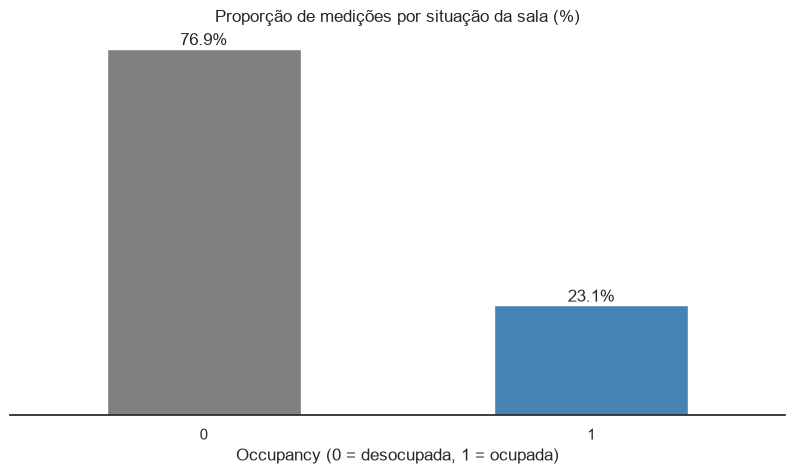

In [12]:
ax = proporcao.plot(kind="bar", color=["gray", "steelblue"])
ax.set_title("Proporção de medições por situação da sala (%)")
ax.set_xlabel("Occupancy (0 = desocupada, 1 = ocupada)")
ax.set_ylabel("")
ax.set_yticks([])
ax.spines[["top", "right", "left"]].set_visible(False)
ax.bar_label(ax.containers[0], fmt="%.1f%%")
plt.xticks(rotation=0)
plt.show()

**76,9%** das medições correspondem a salas desocupadas e **23,1%** a salas ocupadas. As classes são desbalanceadas: um modelo que respondesse sempre "desocupada" teria 76,9% de acurácia sem aprender nada. Esse valor serve como **referência mínima**: os modelos só têm valor real se superarem esse patamar com folga.

### Correlação entre as variáveis

Calcular a correlação de Pearson entre todas as variáveis e exibir o resultado em um mapa de calor. A correlação varia de -1 a 1: valores próximos de 1 indicam que duas variáveis crescem juntas, próximos de -1 que uma cresce enquanto a outra diminui, e próximos de 0 que não há relação linear. A linha de `Occupancy` mostra quais sensores têm maior relação com a ocupação da sala.

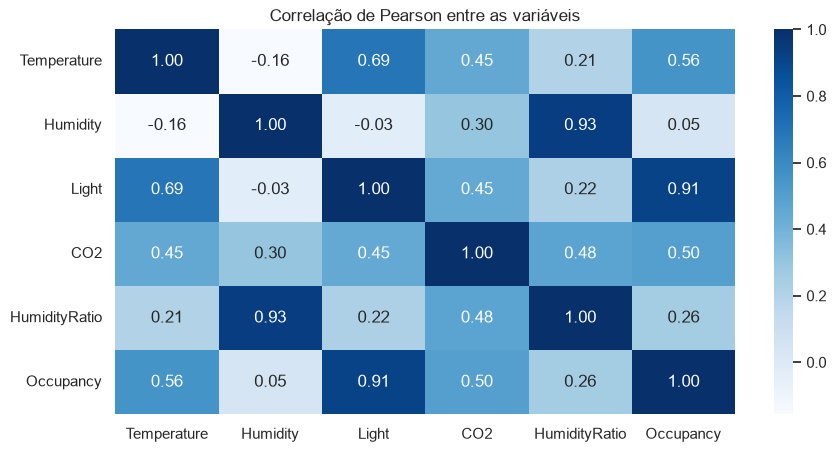

In [13]:
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="Blues")
plt.title("Correlação de Pearson entre as variáveis")
plt.show()

Correlação de cada sensor com `Occupancy`, da mais forte para a mais fraca:

| Sensor | Correlação |
|---|---|
| `Light` | 0,91 |
| `Temperature` | 0,56 |
| `CO2` | 0,50 |
| `HumidityRatio` | 0,26 |
| `Humidity` | 0,05 |

Também chama atenção a correlação de **0,93 entre `Humidity` e `HumidityRatio`**: as duas variáveis carregam praticamente a mesma informação, o que é esperado, já que `HumidityRatio` é calculada a partir da umidade e da temperatura.

### Análise exploratória: principais conclusões e estratégia de modelagem

**1. A luminosidade é o sinal mais forte de ocupação.** `Light` tem correlação de 0,91 com `Occupancy`, e seu histograma mostra dois grupos bem definidos: luz apagada (0 Lux) e luz acesa (entre 400 e 500 Lux). Isso faz sentido no contexto predial: quando há pessoas na sala, a iluminação costuma estar ligada. É provável que os dois modelos dependam fortemente dessa variável e alcancem acurácias altas.

**2. CO2 e temperatura complementam a informação.** `CO2` (0,50) e `Temperature` (0,56) têm correlação moderada com a ocupação. A presença de pessoas aumenta o CO2 pela respiração e eleva a temperatura do ambiente. São variáveis importantes para os casos em que a luz sozinha não basta, como uma sala vazia com luz esquecida acesa ou uma sala ocupada iluminada apenas pela luz natural.

**3. A umidade relativa quase não se relaciona com a ocupação.** `Humidity` tem correlação de apenas 0,05 com `Occupancy`. Além disso, ela é altamente correlacionada com `HumidityRatio` (0,93), ou seja, as duas repetem a mesma informação. Neste projeto, todas as variáveis serão mantidas, conforme o enunciado, mas a redundância fica registrada como ponto de atenção.

**Como essas observações direcionam a modelagem:**

- **Métrica e referência:** com 76,9% das medições na classe "desocupada", a acurácia precisa ser comparada com esse patamar. Um modelo com 80% de acurácia, por exemplo, seria apenas um pouco melhor do que sempre responder "desocupada".
- **Divisão estratificada (Fase 4):** o desbalanceamento exige `stratify=y`, para que treino e teste mantenham a mesma proporção de salas ocupadas e vazias.
- **Escala (Fase 5):** os sensores têm escalas muito diferentes (`Light` vai de 0 a quase 1.700, `HumidityRatio` fica abaixo de 0,007). Sem padronização, o KNN, que calcula distâncias, seria dominado por `Light` e `CO2`. A Árvore de Decisão não sofre esse efeito.
- **Assimetria (Fase 2):** `Light` e `CO2` são fortemente assimétricas, o que indica a **mediana** como medida mais adequada para uma eventual imputação de valores ausentes.